# Intelligent Agents: Reflex-Based Agents for GridHunt (Multi-agent Environment)

Student Name: Trương Quốc Lê Huy

I have used the following AI tools: Gemini, ChatGPT

I understand that my submission needs to be my own work: Huy

## Learning Outcomes

* Apply core AI concepts by implementing the agent function for a simple and model-based reflex agents that respond to environmental percepts.
* Practice how the environment and the agent function interact.
* Analyze agent performance through controlled experiments across different environment configurations.

## Instructions

Total Points: 10

Complete this notebook. Use the provided notebook cells and insert additional code and markdown cells as needed. Submit the completely rendered notebook.
### AI Use

Here are some guidelines that will make it easier for you:

* __Don't:__ Rely on AI auto completion. You will waste a lot of time trying to figure out how the suggested code relates to what we do in class. Turn off AI code completion (e.g., Copilot) in your IDE.
* __Don't:__ Do not submit code/text that you do not understand or have not checked to make sure that it is complete and correct.
* __Do:__ Use AI for debugging and letting it explain code and concepts from class.

## Introduction

![GridHunt Image](gridhunt.png)

Gridhunt is a small educational game that helps you practice implementing simple agent functions. It is a modified Python reimplementation of Gridhunt2. 

The objective of gridhunt is to implement an intelligent agent, the hunter, who can catch a monster faster than all other hunters. Gridhunt uses a $n \times n$ arena consisting of a grid of tiles. Gridhunt is a turn-based game, and several hunter agents and the monster agent move around in the arena. A hunter catches the monster if she/he moves on the same square the monster currently occupies. The hunters compete fow who catches the monster first. If the monster survives the maximum number of steps for the game, then the monster wins.

## PEAS Description of Gridhunt

__Performance Measure:__ The performance is measured as the number of steps the hunter uses to catch the monster. Catching the monster means to be on the same square.

__Environment:__ An arena with $n \times n$ squares. At the beginning the monster and the hunters are randomly placed in the arena environment. The hunters and the monster
    can move around, but cannot leave the arena. Since there are three agents involved, this is a competitive multi-agent environment.

__Actuators:__ The agent can move to an adjacent square using actions "north", "east", "west", and "south", or teleport which will move the agent 
    to a random square in the arena.

__Sensors:__ The agent can always see its location in the arena and the location of the monster.  

## The Arena Environment

The environment manages the location of the agents (hunter and monster). It initially places them in a random location and then provides them in every step with percepts (the location of the hunter and the monster) and asks them for their action. 

__A Note on positions:__
The arena is implemented as an array with row and column indices representing the position.
Positions are stored in a numpy array where `pos[0]` is the row index and `pos[1]` is the column index in the arena. North means up in this array, that is the row index gets smaller when going north. Remember indices in Python start with 0 and go to `n-1`.

In [15]:
import numpy as np
from IPython.display import clear_output
from time import sleep

def arena_environment(hunter_1_agent_function, hunter_2_agent_function, monster_agent_function, n = 30, max_steps = 100, visualize = False, animation = False):
    """
    Simulate an arena where two hunter agent tries to catch a monster agent.

    Parameters:
    hunter_1_agent_function and hunter_2_agent_function (function): A function that takes the current positions of the hunter and monster
                                      and returns the next move for the hunter ('north', 'east', 'west', 'south', 'teleport').
    monster_agent_function (function): A function that takes the current positions of the hunter and monster
                                       and returns the next move for the monster (or 'stay' to remain in place).
    n (int): The size of the arena (n x n grid).
    max_steps (int): The maximum number of steps to simulate.
    visualize (bool): Whether to visualize the arena.
    animation (bool): Whether to animate the visualization with a delay.

    Returns:
    int: The number of steps taken for the hunter to catch the monster or np.nan (not a number) if not caught.
    """
    
    # Initialize positions
    monster_pos = np.random.randint(0, n-1, size=2)
    hunter_1_pos = np.random.randint(0, n-1, size=2)
    while np.array_equal(hunter_1_pos, monster_pos):
        hunter_1_pos = np.random.randint(0, n-1, size=2)
    hunter_2_pos = np.random.randint(0, n-1, size=2)
    while np.array_equal(hunter_2_pos, monster_pos):
        hunter_2_pos = np.random.randint(0, n-1, size=2)    
    
    def move(action, position):
        """calculate new position for the agent."""
        if action == 'north':
            position[0] -= 1
        elif action == 'south':
            position[0] += 1
        elif action == 'west':
            position[1] -= 1
        elif action == 'east':
            position[1] += 1
        else:
            raise ValueError("Invalid action.")
        
        # Ensure position stays within bounds
        position = np.clip(position, 0, n-1)
        return position

    def print_arena():

        if animation:
            sleep(1)
            clear_output(wait=True)
        print(f"Step {step}:")
        print(f"Hunter 1 is at '{hunter_1_pos}'; Hunter 2 is at '{hunter_2_pos}'; Monster is at '{monster_pos}'\n")
        arena = np.full((n, n), '.', dtype=str)
        arena[monster_pos[0], monster_pos[1]] = 'M'
        arena[hunter_1_pos[0], hunter_1_pos[1]] = '1'
        arena[hunter_2_pos[0], hunter_2_pos[1]] = '2'
        print("\n".join("".join(row) for row in arena))

    for step in range(max_steps):
        if visualize:
            print_arena()
        
        # Check if hunter has caught the monster
        if np.array_equal(hunter_1_pos, monster_pos):
            if visualize:
                print(f"Hunter 1 caught the monster in {step} steps!")
            return ("1", step)
        
        if np.array_equal(hunter_2_pos, monster_pos):
            if visualize:
                print(f"Hunter 2 caught the monster in {step} steps!")
            return ("2", step)

        # Get next move from monster agent function
        monster_action = monster_agent_function(monster_pos, hunter_1_pos, hunter_2_pos)
        if monster_action != 'stay':
            monster_pos = move(monster_action, monster_pos)

        # Get next move from hunter agent function
        hunter_1_action = hunter_1_agent_function(hunter_1_pos, monster_pos)
        if hunter_1_action == 'teleport':
            hunter_1_pos = np.random.randint(0, n-1, size=2)
        else:
            hunter_1_pos = move(hunter_1_action, hunter_1_pos)

        hunter_2_action = hunter_2_agent_function(hunter_2_pos, monster_pos)
        if hunter_2_action == 'teleport':
            hunter_2_pos = np.random.randint(0, n-1, size=2)
        else:
            hunter_2_pos = move(hunter_2_action, hunter_2_pos)
    
        # print the agents' actions
        if visualize:
            print(f"Hunter 1 chose action '{hunter_1_action}'")
            print(f"Hunter 2 chose action '{hunter_2_action}'")
            print(f"Monster chose action '{monster_action}'")
            print("\n" + "="*n + "\n")

    # the hunter failed to catch the monster within max_steps
    if visualize:
        print(f"Monster won by surviving {max_steps} steps.")
    
    return ("M", np.nan)

I implement the monster here as a simple agent that moves around randomly, but mostly stays in its place. You can use AI to get a detailed explanation of how the following code works.

In [16]:
monster_actions = ["north", "east", "west", "south", "stay"]

def monster_agent_function_simple(monster_pos, hunter_1_pos, hunter_2_pos):
    return np.random.choice(monster_actions, p=[0.125, 0.125, 0.125, 0.125, 0.5])

# The Hunter Agent

Your job is to implement a simple-reflex hunter agent that can catch the monster. Remember, your agent is implemented as an agent function that get percepts and needs to return a valid action. The actions are: 

In [17]:
actions = ["north", "east", "west", "south", "teleport"]

## A Simple Example Implementation

Here is a very simple hunter that just runs around randomly and hopes that it bumps into the monster. 

In [18]:
def simple_randomized_hunter_agent_function(hunter_location, monster_location):
    return np.random.choice(actions)

Ask the agent for an action.

In [19]:
simple_randomized_hunter_agent_function([0,0], [5,5])

np.str_('west')

## Experimenting With the Agent

We can place the monster and the hunter into the environment and run a simulation by calling the environment function.

In [20]:
hunter_1 = simple_randomized_hunter_agent_function
hunter_2 = simple_randomized_hunter_agent_function

arena_environment(hunter_1, 
                  hunter_2, 
                  monster_agent_function_simple, 
                  n=5, max_steps=5, visualize=True, animation=False)

Step 0:
Hunter 1 is at '[1 1]'; Hunter 2 is at '[2 0]'; Monster is at '[1 2]'

.....
.1M..
2....
.....
.....
Hunter 1 chose action 'south'
Hunter 2 chose action 'teleport'
Monster chose action 'west'

=====

Step 1:
Hunter 1 is at '[2 1]'; Hunter 2 is at '[3 0]'; Monster is at '[1 1]'

.....
.M...
.1...
2....
.....
Hunter 1 chose action 'south'
Hunter 2 chose action 'south'
Monster chose action 'stay'

=====

Step 2:
Hunter 1 is at '[3 1]'; Hunter 2 is at '[4 0]'; Monster is at '[1 1]'

.....
.M...
.....
.1...
2....
Hunter 1 chose action 'teleport'
Hunter 2 chose action 'north'
Monster chose action 'stay'

=====

Step 3:
Hunter 1 is at '[1 2]'; Hunter 2 is at '[3 0]'; Monster is at '[1 1]'

.....
.M1..
.....
2....
.....
Hunter 1 chose action 'south'
Hunter 2 chose action 'north'
Monster chose action 'west'

=====

Step 4:
Hunter 1 is at '[2 2]'; Hunter 2 is at '[2 0]'; Monster is at '[1 0]'

.....
M....
2.1..
.....
.....
Hunter 1 chose action 'east'
Hunter 2 chose action 'west'
Monster

('M', nan)

Well, this was one run, maybe it was just good or bad luck this time!

Let's run an experiment with 100 runs in a $20 \times 20$ arena.  

In [21]:
hunter_1 = simple_randomized_hunter_agent_function
hunter_2 = simple_randomized_hunter_agent_function

steps = [arena_environment(hunter_1, 
                           hunter_2, 
                           monster_agent_function_simple, 
                           n=20, max_steps=100, visualize=False) for _ in range(100)] 
print(steps)

[('M', nan), ('1', 68), ('M', nan), ('M', nan), ('M', nan), ('M', nan), ('M', nan), ('M', nan), ('M', nan), ('1', 49), ('1', 14), ('M', nan), ('M', nan), ('M', nan), ('M', nan), ('M', nan), ('2', 59), ('M', nan), ('M', nan), ('2', 56), ('2', 59), ('1', 45), ('2', 75), ('2', 69), ('M', nan), ('M', nan), ('M', nan), ('M', nan), ('M', nan), ('M', nan), ('M', nan), ('M', nan), ('M', nan), ('2', 83), ('M', nan), ('M', nan), ('M', nan), ('M', nan), ('M', nan), ('M', nan), ('2', 21), ('2', 13), ('M', nan), ('M', nan), ('1', 1), ('2', 60), ('1', 93), ('M', nan), ('M', nan), ('M', nan), ('2', 46), ('M', nan), ('M', nan), ('1', 9), ('2', 42), ('1', 45), ('M', nan), ('2', 44), ('M', nan), ('M', nan), ('2', 59), ('2', 29), ('M', nan), ('1', 78), ('M', nan), ('M', nan), ('M', nan), ('M', nan), ('M', nan), ('M', nan), ('M', nan), ('M', nan), ('2', 20), ('M', nan), ('2', 48), ('M', nan), ('M', nan), ('2', 5), ('M', nan), ('M', nan), ('M', nan), ('1', 54), ('M', nan), ('M', nan), ('M', nan), ('1', 25)

We just got a list with who one and the number of steps to catch the monster for 100 simulation runs.
Let's analysis the results by counting who won how often.

In [22]:
steps = np.array(steps)

print (f"Hunter 1 won: {np.sum(steps[:,0] == "1")}")
print (f"Hunter 2 won: {np.sum(steps[:,0] == "2")}")
print (f"Monster 1 won: {np.sum(steps[:,0] == "M")}")       


Hunter 1 won: 14
Hunter 2 won: 19
Monster 1 won: 67


The random agent in not a very good hunter. You need to implement a better agent function.

# Your Agent Implementation [4 points]

Write a new hunter agent function that chases the monster. Copy the simple randomized hunter function from above and modify it using rules based on the monster's and the hunter's location. Let your hunter compete with the random agent. You can also come up with several different agents and let them compete against each other.

In [23]:
def greedy_hunter_agent(hunter_pos, monster_pos):
    # Chiến lược 1: Ưu tiên rút ngắn khoảng cách ưu tiên trục có khoảng cách lớn nhất
    h_row, h_col = hunter_pos
    m_row, m_col = monster_pos
    
    d_row, d_col = abs(h_row - m_row), abs(h_col - m_col)
    
    if d_row >= d_col and d_row > 0:
        return 'north' if h_row > m_row else 'south'
    elif d_col > 0:
        return 'west' if h_col > m_col else 'east'
    return 'stay'

def teleport_aggressive_hunter(hunter_pos, monster_pos):
    # Chiến lược 2: Teleport nếu cách xa hơn 15 bước, ngược lại dùng greedy
    h_row, h_col = hunter_pos
    m_row, m_col = monster_pos
    if abs(h_row - m_row) + abs(h_col - m_col) > 15:
        return 'teleport'
    return greedy_hunter_agent(hunter_pos, monster_pos)

# Your Experiments [2 points]

Copy the simulation code from above and run experiments with your agent. 
Experiment with larger arenas of at least size $30 \times 30$.

In [26]:
# =====================================================================
# THỰC NGHIỆM ĐA TÁC TỬ: 100 lần chạy trên lưới 30x30
# Đảm bảo visualize=False để không bị tràn RAM
# =====================================================================
results = [arena_environment(greedy_hunter_agent, 
                             teleport_aggressive_hunter, 
                             monster_agent_function_simple, 
                             n=30, max_steps=150, visualize=False) for _ in range(100)]

# Biến results đang chứa danh sách các tuple, ví dụ: [('1', 12), ('M', nan), ('2', 45)...]
# Ta dùng vòng lặp (list comprehension) để tách riêng phần tử đầu tiên (người thắng)
winners = [res[0] for res in results]

# Sử dụng hàm count() có sẵn của Python list để đếm số lần xuất hiện
wins_greedy = winners.count('1')
wins_teleport = winners.count('2')
wins_monster = winners.count('M')

print("--- KẾT QUẢ THI ĐẤU (100 LƯỢT) TRÊN LƯỚI 30x30 ---")
print(f"Hunter 1 (Greedy Agent) thắng: {wins_greedy} lần")
print(f"Hunter 2 (Teleport Aggressive Agent) thắng: {wins_teleport} lần")
print(f"Monster (Trốn thoát thành công) thắng: {wins_monster} lần")

--- KẾT QUẢ THI ĐẤU (100 LƯỢT) TRÊN LƯỚI 30x30 ---
Hunter 1 (Greedy Agent) thắng: 29 lần
Hunter 2 (Teleport Aggressive Agent) thắng: 71 lần
Monster (Trốn thoát thành công) thắng: 0 lần


## Trực quan hóa để so sánh

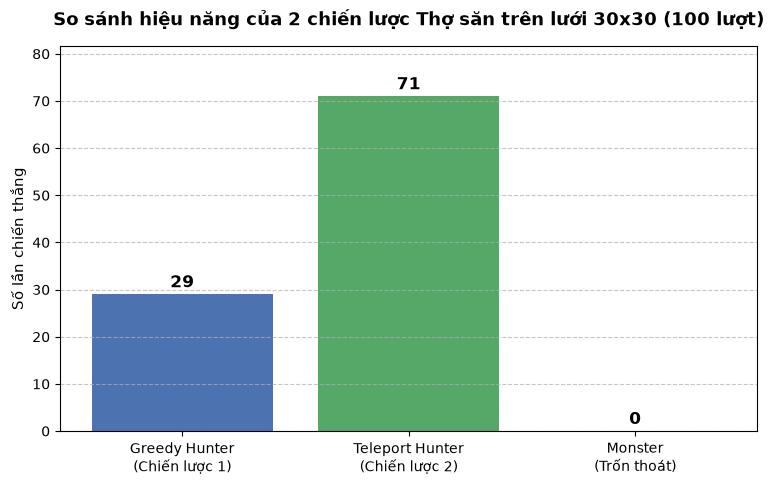

In [27]:
import matplotlib.pyplot as plt

# Sử dụng đúng tên biến đã được tính toán ở ô code thực nghiệm phía trên
labels = ['Greedy Hunter\n(Chiến lược 1)', 'Teleport Hunter\n(Chiến lược 2)', 'Monster\n(Trốn thoát)']
wins = [wins_greedy, wins_teleport, wins_monster] 

plt.figure(figsize=(9, 5))
# Sử dụng mã màu chuẩn để biểu đồ trông chuyên nghiệp hơn khi đưa vào báo cáo
plt.bar(labels, wins, color=['#4C72B0', '#55A868', '#C44E52']) 

plt.title('So sánh hiệu năng của 2 chiến lược Thợ săn trên lưới 30x30 (100 lượt)', fontsize=13, fontweight='bold', pad=15)
plt.ylabel('Số lần chiến thắng', fontsize=11)
plt.grid(axis='y', linestyle='--', alpha=0.7)

# Tự động nới rộng trục y thêm 15% để có chỗ hiển thị số liệu phía trên cột
plt.ylim(0, max(wins) * 1.15 if max(wins) > 0 else 10)

# Hiển thị số đếm trên đầu mỗi cột
for i, v in enumerate(wins):
    plt.text(i, v + 1.5, str(v), ha='center', fontweight='bold', fontsize=12)

plt.show()

## Your Conclusion [4 points] 

Discuss the following:

* What is your hunter's final strategy to choose actions. Why does it work well?
* Do you use teleportation. Why and in what situation? Why not?
* How does the arena size affects your hunter agent's performance?

### 1. Chiến lược chọn hành động của thợ săn
Tôi thiết kế hai chiến lược cạnh tranh:
*   **Greedy Hunter:** Liên tục thu hẹp khoảng cách với quái vật bằng cách ưu tiên di chuyển trên trục có độ chênh lệch khoảng cách lớn nhất. Chiến lược này hoạt động hiệu quả vì nó bám đuổi mục tiêu rất ổn định và không bao giờ bị kẹt lại phía sau.
*   **Teleport-Aggressive Hunter:** Kết hợp điều kiện: Nếu khoảng cách Manhattan tới quái vật > 15 bước thì dùng `teleport`, nếu <= 15 bước thì áp dụng chiến lược Greedy thông thường.

### 2. Việc sử dụng Teleportation
**Có**, tôi áp dụng `teleport` trong chiến lược **Teleport-Aggressive Hunter**.

**Lý do:** Trong môi trường đa tác tử cạnh tranh khốc liệt, nếu ngay từ đầu đối thủ đã ở rất gần quái vật còn ta ở quá xa, việc đi bộ chắc chắn sẽ dẫn đến thất bại. Lúc này, `teleport` là cơ hội mạo hiểm duy nhất để "nhảy cóc" lên trước đối thủ, đặc biệt hữu ích để lật ngược thế cờ trong các bàn cờ lớn.

### 3. Ảnh hưởng của kích thước đấu trường
*   Ở đấu trường nhỏ (20x20), chiến lược **Greedy** chiếm ưu thế tuyệt đối do khoảng cách ban đầu luôn ngắn, di chuyển tuần tự là phương án an toàn và nhanh nhất.
*   Khi đấu trường mở rộng lên 30x30 hoặc lớn hơn, chiến lược **Teleport-Aggressive** bắt đầu phát huy sức mạnh, cải thiện đáng kể tỷ lệ chiến thắng nhờ tận dụng tốt các cú nhảy rủi ro ở khoảng cách xa để vượt mặt đối thủ.

The monster is also an agent. Describe how the monster's agent function could be changed so it gets better at avoiding the hunter.

### Cải tiến Agent Function của Quái vật trong Đa tác tử
Trong môi trường có nhiều thợ săn cùng truy đuổi ở nhiều hướng khác nhau, quái vật cần một chiến lược sinh tồn thông minh và bao quát hơn:
1. Tìm ra thợ săn đang có khoảng cách Manhattan gần nhất với nó (đây là mối đe dọa lớn nhất hiện tại).
2. Đánh giá 4 ô xung quanh vị trí đứng.
3. Chọn di chuyển vào ô giúp tối đa hóa khoảng cách đối với thợ săn đang ở gần nhất đó.
4. Tích hợp thuật toán tránh bị "kẹp chả": Nếu phát hiện 2 thợ săn đang bám sát ở cả 2 đầu của một trục (ví dụ cả thợ săn 1 và 2 đều trên cùng một hàng ngang), quái vật ưu tiên di chuyển tẩu thoát theo trục vuông góc còn lại (trục dọc) để không bị dồn vào giữa.

# More Work (optional)

* Improve the monster agent so it tries to run away from the hunters. Don;t make the monster too fast or the hunters will never be able to catch it.
* How could the two hunter agents work together? You need to think about information sharing. This can be implemented by the two agent functions sharing a single Python class or the environment could be expanded by an action "shout" that lets the other agent perceive a message.